# Module 04 — Differential Calculus for ML

This notebook is the runnable companion to the concept guide. It builds every object of the
module in plain NumPy — finite differences, activation derivatives, gradients, Jacobians,
Hessians, Taylor models, the matrix-calculus identities and the gradients of ML losses — and
checks each analytic formula against a numerical one.

Read the [concept guide](README.md) first, or keep it open alongside: each section below
mirrors a numbered section there. Run the cells top to bottom; the "Try it yourself"
prompts are invitations to break things and see what happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=5, suppress=True)

## 1. The derivative and its numerical approximation

The derivative is the limit of a difference quotient,

$$f'(x) = \lim_{h\to 0}\frac{f(x+h)-f(x)}{h},$$

and a computer approximates it with a *finite* $h$. Two schemes:

| scheme | formula | truncation error |
|---|---|---|
| forward | $\dfrac{f(x+h)-f(x)}{h}$ | $O(h)$ |
| central | $\dfrac{f(x+h)-f(x-h)}{2h}$ | $O(h^2)$ |

Truncation error shrinks with $h$, but *round-off* error grows like $\varepsilon|f|/h$
(with machine epsilon $\varepsilon \approx 2.2\times 10^{-16}$), because two nearly equal
numbers are subtracted and the difference is divided by something tiny. Let us see both effects.

forward, h=0.1 : 12.61000000000001    error 0.6100000000000101
central, h=0.1 : 12.010000000000009    error 0.010000000000008669


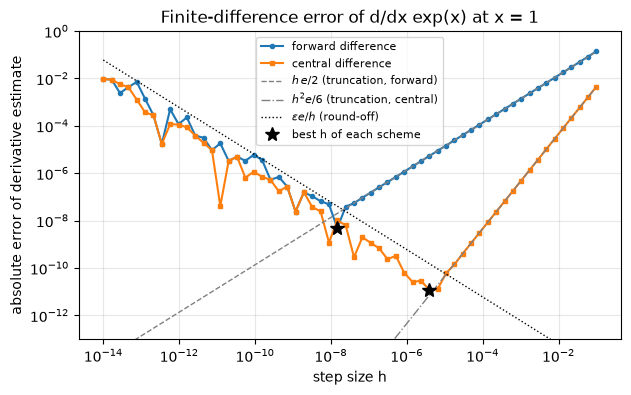

best forward : h = 1.5e-08, error 4.8e-09
best central : h = 3.9e-06, error 1.2e-11


In [2]:
def fwd_diff(f, x, h):
    return (f(x + h) - f(x)) / h

def central_diff(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

# Hand example from the guide: f(x) = x^3 at x = 2, exact derivative 12
f = lambda x: x**3
print("forward, h=0.1 :", fwd_diff(f, 2.0, 0.1), "   error", fwd_diff(f, 2.0, 0.1) - 12)
print("central, h=0.1 :", central_diff(f, 2.0, 0.1), "   error", central_diff(f, 2.0, 0.1) - 12)

# Now sweep h over 14 decades for f(x) = exp(x) at x = 1 (exact derivative e)
g, x0, exact = np.exp, 1.0, np.e
hs = np.logspace(-14, -1, 60)
err_f = np.abs(fwd_diff(g, x0, hs) - exact)
err_c = np.abs(central_diff(g, x0, hs) - exact)
i_f, i_c = np.argmin(err_f), np.argmin(err_c)

plt.loglog(hs, err_f, "o-", ms=3, label="forward difference")
plt.loglog(hs, err_c, "s-", ms=3, label="central difference")
plt.loglog(hs, hs * np.e / 2, "--", lw=1, color="gray", label=r"$h\,e/2$ (truncation, forward)")
plt.loglog(hs, hs**2 * np.e / 6, "-.", lw=1, color="gray", label=r"$h^2 e/6$ (truncation, central)")
plt.loglog(hs, 2.2e-16 * np.e / hs, ":", lw=1, color="black", label=r"$\varepsilon e / h$ (round-off)")
plt.loglog(hs[[i_f, i_c]], [err_f[i_f], err_c[i_c]], "k*", ms=10, label="best h of each scheme")
plt.ylim(1e-13, 1)
plt.xlabel("step size h"); plt.ylabel("absolute error of derivative estimate")
plt.title("Finite-difference error of d/dx exp(x) at x = 1")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print(f"best forward : h = {hs[i_f]:.1e}, error {err_f[i_f]:.1e}")
print(f"best central : h = {hs[i_c]:.1e}, error {err_c[i_c]:.1e}")

Notice the V shape. On the right, both curves are straight lines that follow their grey
truncation references: slope 1 for the forward scheme (error $\propto h$) and slope 2 for the
central scheme (error $\propto h^2$), exactly the truncation orders. On the left, both ride the
dotted round-off line $\varepsilon e/h$, which *rises* as $h$ shrinks. The best step (black stars)
is where the two meet: about $10^{-8}$ for forward (error $\sim 10^{-8}$) and about
$4\times10^{-6}$ for central (error $\sim 10^{-11}$). Below $h \approx 10^{-12}$ the error is pure
round-off and only two to four significant digits survive — "smaller is safer" is false.

For the hand example, the forward error $0.61$ matches $\tfrac{h}{2}f''(2) = 0.05\cdot 12 = 0.6$,
and the central error $0.01$ matches $\tfrac{h^2}{6}f'''(2) = \tfrac{0.01}{6}\cdot 6 = 0.01$.

**Try it yourself:** replace `np.exp` by `np.sin` (exact derivative `np.cos(1.0)`), or cast
inputs to `np.float32` — where does the V's bottom move, and why?

Why is the central scheme so much better? Draw the two chords for the hand example $f(x) = x^3$
at $x = 2$, with a large step $h = 0.5$ so that they are visible.

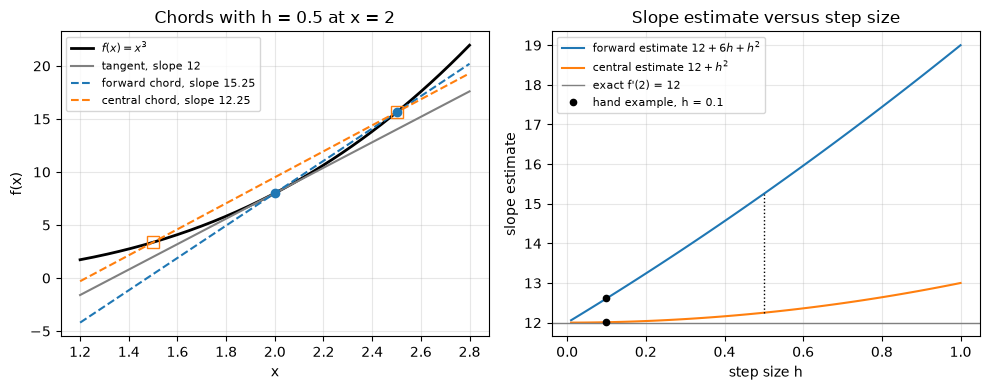

In [3]:
a1, h1 = 2.0, 0.5                                   # f(x) = x^3 from the cell above
s_fwd, s_cen = fwd_diff(f, a1, h1), central_diff(f, a1, h1)
xx = np.linspace(1.2, 2.8, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(xx, f(xx), "k", lw=2, label=r"$f(x) = x^3$")
ax1.plot(xx, f(a1) + 12 * (xx - a1), color="gray", lw=1.5, label="tangent, slope 12")
ax1.plot(xx, f(a1) + s_fwd * (xx - a1), "--", color="C0", label=f"forward chord, slope {s_fwd:.2f}")
ax1.plot(xx, f(a1 - h1) + s_cen * (xx - (a1 - h1)), "--", color="C1", label=f"central chord, slope {s_cen:.2f}")
ax1.plot([a1, a1 + h1], [f(a1), f(a1 + h1)], "o", color="C0")
ax1.plot([a1 - h1, a1 + h1], [f(a1 - h1), f(a1 + h1)], "s", color="C1", mfc="none", ms=8)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("Chords with h = 0.5 at x = 2")
ax1.legend(fontsize=8, loc="upper left"); ax1.grid(alpha=0.3)

hh = np.linspace(0.01, 1, 100)
ax2.plot(hh, fwd_diff(f, a1, hh), color="C0", label=r"forward estimate $12 + 6h + h^2$")
ax2.plot(hh, central_diff(f, a1, hh), color="C1", label=r"central estimate $12 + h^2$")
ax2.axhline(12, color="gray", lw=1, label="exact f'(2) = 12")
ax2.plot([0.1, 0.1], [central_diff(f, a1, 0.1), fwd_diff(f, a1, 0.1)], "k.", ms=9, label="hand example, h = 0.1")
ax2.plot([h1, h1], [s_cen, s_fwd], "k:", lw=1)
ax2.set_xlabel("step size h"); ax2.set_ylabel("slope estimate"); ax2.set_title("Slope estimate versus step size")
ax2.legend(fontsize=8, loc="upper left"); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Notice that** the central chord (slope $12.25$) is almost parallel to the tangent (slope $12$),
while the forward chord (slope $15.25$) is visibly steeper. The one-sided chord picks up the
curvature term $\tfrac{h}{2}f''(2) = 3$; the symmetric chord cancels it and keeps only
$\tfrac{h^2}{6}f'''(2) = 0.25$. In the right panel the forward estimate $12 + 6h + h^2$ leaves
$12$ with slope $f''(2)/2 = 6$, and the central one follows the flat parabola $12 + h^2$:
these are the $O(h)$ and $O(h^2)$ of the table. The two black dots at $h = 0.1$ are the hand
example, $12.61$ and $12.01$; the dotted segment at $h = 0.5$ is the gap between the two chords
on the left.

## 2. The rules you actually use — activation functions and their derivatives

The chain rule says that composed functions multiply their slopes. Applied to the sigmoid
$\sigma(z) = 1/(1+e^{-z})$ it gives $\sigma'(z) = \sigma(z)(1-\sigma(z))$; for
$\tanh$ it gives $1 - \tanh^2 z$; $\mathrm{softplus}(z) = \ln(1+e^z)$ has derivative
$\sigma(z)$; and $\mathrm{ReLU}(z) = \max(0,z)$ has derivative $\mathbb{1}[z>0]$ (with any
value in $[0,1]$ acceptable as a subgradient at $z = 0$).

Below we implement each derivative *from the formula* and confirm it against a central
difference — the habit this module wants you to form.

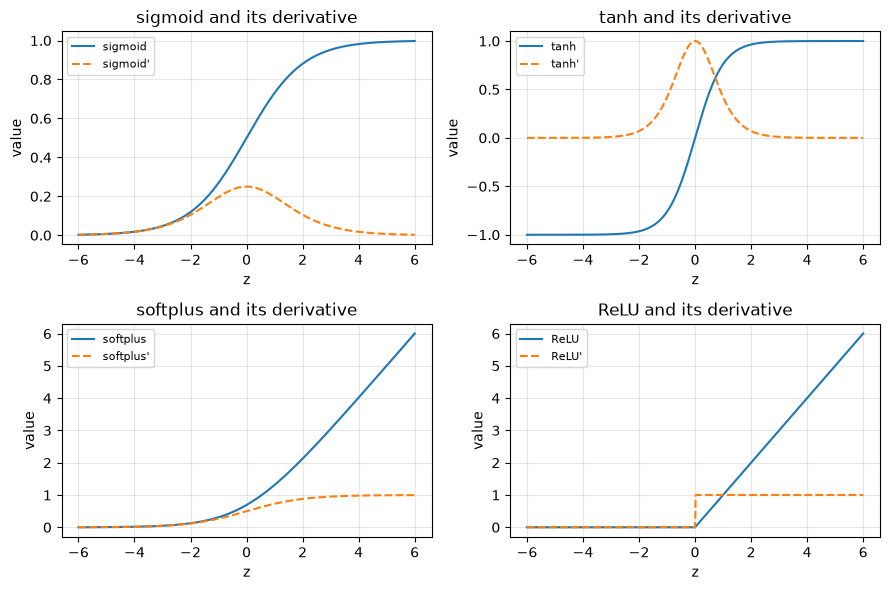

sigmoid   max |analytic - numerical| = 6.92e-11
tanh      max |analytic - numerical| = 4.57e-11
softplus  max |analytic - numerical| = 2.39e-10
ReLU      max |analytic - numerical| = 1.40e-10

max of sigma'(z) = 0.25   (at z = 0: exactly 1/4)
sigma'(2) = 0.10499358540350662   sigma'(5) = 0.006648056670790033


In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

activations = {
    "sigmoid":  (sigmoid,                         lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":     (np.tanh,                         lambda z: 1 - np.tanh(z)**2),
    "softplus": (lambda z: np.logaddexp(0.0, z),  sigmoid),
    "ReLU":     (lambda z: np.maximum(0.0, z),    lambda z: (z > 0).astype(float)),
}

z = np.linspace(-6, 6, 601)
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (name, (act, dact)) in zip(axes.ravel(), activations.items()):
    ax.plot(z, act(z), label=name)
    ax.plot(z, dact(z), "--", label=name + "'")
    ax.set_title(name + " and its derivative"); ax.set_xlabel("z"); ax.set_ylabel("value")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

# analytic vs numerical derivative, away from the ReLU kink
zz = np.linspace(-4, 4, 17) + 0.013
for name, (act, dact) in activations.items():
    num = central_diff(act, zz, 1e-6)
    print(f"{name:9s} max |analytic - numerical| = {np.max(np.abs(dact(zz) - num)):.2e}")

print("\nmax of sigma'(z) =", np.max(activations['sigmoid'][1](z)), "  (at z = 0: exactly 1/4)")
print("sigma'(2) =", activations['sigmoid'][1](2.0), "  sigma'(5) =", activations['sigmoid'][1](5.0))

Every analytic derivative agrees with the numerical one to about $10^{-10}$. Two things to
notice in the plots: the sigmoid's derivative never exceeds $1/4$ and is already $0.105$ at
$z = 2$ — this *saturation* is the origin of vanishing gradients; and ReLU's derivative is
exactly $1$ wherever the unit is active, so gradients pass through unchanged.

A one-neuron network makes the chain rule concrete: $z = wx + b$, $p = \sigma(z)$,
$L = (p - y)^2$. Then $\dfrac{dL}{dw} = \dfrac{dL}{dp}\dfrac{dp}{dz}\dfrac{dz}{dw} = 2(p-y)\cdot p(1-p)\cdot x$.

In [5]:
w, b, x, y = 0.5, 0.0, 2.0, 1.0
z = w * x + b
p = sigmoid(z)
L = (p - y)**2
dL_dw = 2 * (p - y) * p * (1 - p) * x
print(f"forward : z = {z}, p = {p:.4f}, L = {L:.4f}")
print(f"backward: dL/dw = 2(p-y) * p(1-p) * x = {dL_dw:.4f}")
print("numerical check:", central_diff(lambda w_: (sigmoid(w_ * x + b) - y)**2, w, 1e-6))

# why sigmoid networks vanish: ten layers, each contributing at most 1/4
print("\nten sigmoid layers, best case gradient factor:", 0.25**10)

forward : z = 1.0, p = 0.7311, L = 0.0723
backward: dL/dw = 2(p-y) * p(1-p) * x = -0.2115
numerical check: -0.21150837112987597

ten sigmoid layers, best case gradient factor: 9.5367431640625e-07


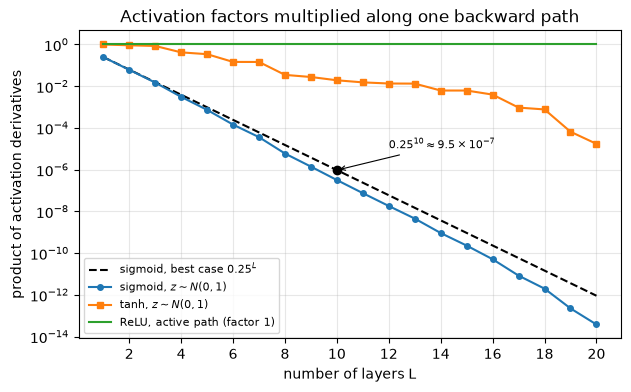

L = 10: sigmoid 3.2e-07   tanh 1.9e-02   best-case sigmoid 9.5e-07
L = 20: sigmoid 3.8e-14   tanh 1.7e-05   best-case sigmoid 9.1e-13


In [6]:
# the same product layer by layer: one backward path through L layers, one pre-activation per layer
rng_v = np.random.default_rng(7)               # a local generator, so the global rng stream is untouched
depth = np.arange(1, 21)
z_path = rng_v.standard_normal(depth.size)     # pre-activations z ~ N(0, 1)
sig_prod = np.cumprod(sigmoid(z_path) * (1 - sigmoid(z_path)))
tanh_prod = np.cumprod(1 - np.tanh(z_path)**2)

plt.semilogy(depth, 0.25**depth, "k--", label=r"sigmoid, best case $0.25^L$")
plt.semilogy(depth, sig_prod, "o-", ms=4, label=r"sigmoid, $z \sim N(0, 1)$")
plt.semilogy(depth, tanh_prod, "s-", ms=4, label=r"tanh, $z \sim N(0, 1)$")
plt.semilogy(depth, np.ones(depth.size), color="C2", label="ReLU, active path (factor 1)")
plt.semilogy([10], [0.25**10], "ko")
plt.annotate(r"$0.25^{10} \approx 9.5\times10^{-7}$", (10, 0.25**10), xytext=(12, 1e-5),
             fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
plt.xticks(np.arange(2, 21, 2))
plt.xlabel("number of layers L"); plt.ylabel("product of activation derivatives")
plt.title("Activation factors multiplied along one backward path")
plt.legend(fontsize=8, loc="lower left"); plt.grid(alpha=0.3); plt.show()
for L_ in (10, 20):
    print(f"L = {L_}: sigmoid {sig_prod[L_ - 1]:.1e}   tanh {tanh_prod[L_ - 1]:.1e}   best-case sigmoid {0.25**L_:.1e}")

**Notice that** even the best case, $0.25^L$, loses six orders of magnitude by $L = 10$ (the
$9.5\times10^{-7}$ printed above), and realistic pre-activations do worse (about
$3\times10^{-7}$ at $L = 10$ and $4\times10^{-14}$ at $L = 20$ here), because $\sigma'(z) < 1/4$
whenever $z \ne 0$. $\tanh$, whose derivative peaks at $1$, decays much more slowly (about
$2\times10^{-2}$ at $L = 10$), and an active ReLU path multiplies by exactly $1$. The weights,
ignored here, multiply into the same product.

## 3. Partial derivatives and the gradient

For $f:\mathbb{R}^n\to\mathbb{R}$, the gradient $\nabla f$ collects the partial derivatives.
The directional derivative along a unit vector $\mathbf{u}$ is $D_{\mathbf{u}} f = \nabla f^\top \mathbf{u}$,
and by Cauchy–Schwarz it is largest when $\mathbf{u}$ points along $\nabla f$ — the gradient is
the **direction of steepest ascent**, with slope $\lVert\nabla f\rVert$, and it is **perpendicular
to level sets**.

We use the guide's example $f(x,y) = x^2 + 3xy$ with $\nabla f = (2x + 3y,\; 3x)$.

analytic gradient at (1,2): [8. 3.]   numerical: [8. 3.]
norm of gradient: 8.54400374531753


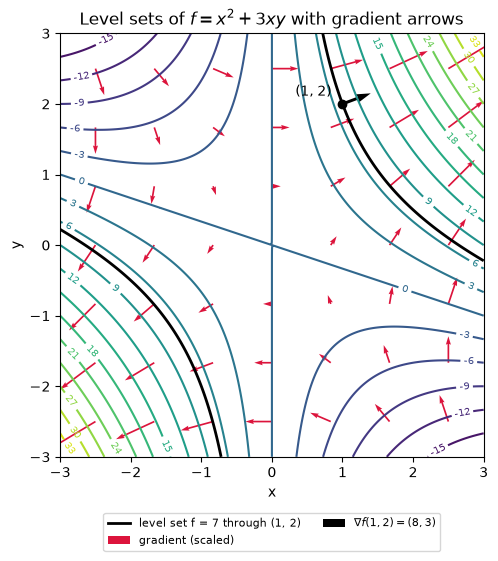

In [7]:
def f2(v):
    x, y = v
    return x**2 + 3 * x * y

def grad_f2(v):
    x, y = v
    return np.array([2 * x + 3 * y, 3 * x])

def grad_fd(f, x, h=1e-6):
    # central-difference gradient for any f: R^n -> R  (built from scratch; reused below)
    x = np.asarray(x, dtype=float)
    g = np.zeros_like(x)
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        g[i] = (f(x + e) - f(x - e)) / (2 * h)
    return g

p0 = np.array([1.0, 2.0])
print("analytic gradient at (1,2):", grad_f2(p0), "  numerical:", grad_fd(f2, p0))
print("norm of gradient:", np.linalg.norm(grad_f2(p0)))

# contour plot with gradient arrows (both come from f2 and grad_f2, which accept stacked grids)
xs = np.linspace(-3, 3, 200); ys = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(xs, ys)
Z = f2(np.stack([X, Y]))
plt.figure(figsize=(6.5, 5.5))
cs = plt.contour(X, Y, Z, levels=20, cmap="viridis")
plt.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
plt.contour(X, Y, Z, levels=[f2(p0)], colors="k", linewidths=2)
plt.plot([], [], "k", lw=2, label=f"level set f = {f2(p0):g} through (1, 2)")
qx, qy = np.meshgrid(np.linspace(-2.5, 2.5, 7), np.linspace(-2.5, 2.5, 7))
gx, gy = grad_f2(np.stack([qx, qy]))
plt.quiver(qx, qy, gx, gy, color="crimson", angles="xy", scale=120, width=0.004, label="gradient (scaled)")
g0 = grad_f2(p0)
plt.quiver(*p0, *g0, color="black", angles="xy", scale=120, width=0.007,
           label=rf"$\nabla f(1, 2) = ({g0[0]:g}, {g0[1]:g})$")
plt.plot(*p0, "ko"); plt.annotate("(1, 2)", p0, xytext=(-34, 6), textcoords="offset points")
plt.gca().set_aspect("equal")
plt.xlabel("x"); plt.ylabel("y"); plt.title(r"Level sets of $f = x^2 + 3xy$ with gradient arrows")
plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.show()

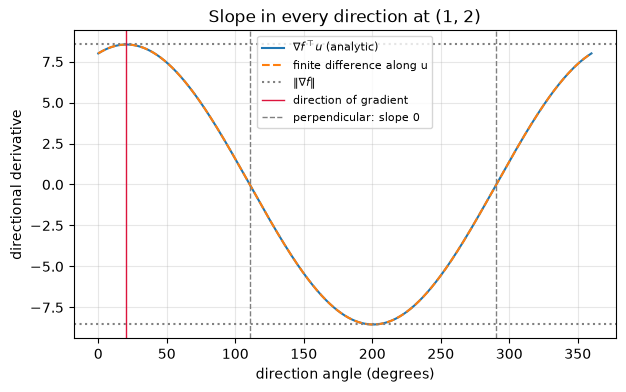

steepest ascent at 20.6 deg; gradient points at 20.6 deg
max slope 8.5440 vs ||grad|| = 8.5440
slope perpendicular to gradient: 0.0


In [8]:
# the directional derivative as a function of direction, at (1, 2)
angles = np.linspace(0, 2 * np.pi, 3601)
U = np.stack([np.cos(angles), np.sin(angles)])           # unit vectors
g = grad_f2(p0)
dir_deriv = g @ U                                        # grad^T u for every direction
numeric = np.array([(f2(p0 + 1e-6 * u) - f2(p0 - 1e-6 * u)) / 2e-6 for u in U.T])

best = angles[np.argmax(dir_deriv)]
grad_angle = np.arctan2(g[1], g[0])
plt.plot(np.degrees(angles), dir_deriv, label=r"$\nabla f^\top u$ (analytic)")
plt.plot(np.degrees(angles), numeric, "--", label="finite difference along u")
plt.axhline(np.linalg.norm(g), color="gray", ls=":", label=r"$\|\nabla f\|$")
plt.axhline(-np.linalg.norm(g), color="gray", ls=":")
plt.axvline(np.degrees(grad_angle), color="crimson", lw=1, label="direction of gradient")
for k, d in enumerate((90, 270)):
    plt.axvline((np.degrees(grad_angle) + d) % 360, color="gray", ls="--", lw=1,
                label="perpendicular: slope 0" if k == 0 else None)
plt.xlabel("direction angle (degrees)"); plt.ylabel("directional derivative")
plt.title("Slope in every direction at (1, 2)"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print(f"steepest ascent at {np.degrees(best):.1f} deg; gradient points at {np.degrees(grad_angle):.1f} deg")
print(f"max slope {dir_deriv.max():.4f} vs ||grad|| = {np.linalg.norm(g):.4f}")
perp = np.array([-g[1], g[0]]) / np.linalg.norm(g)
print("slope perpendicular to gradient:", round(float(g @ perp), 12))

In the contour plot every arrow crosses the level curve through its base at a right angle;
where the contours are dense (steep terrain) the arrows are long. The black arrow is the
gradient $(8, 3)$ at $(1, 2)$, and it is perpendicular to the thick level curve $f = 7$ through
that point. The sinusoid in the second
plot *is* the Cauchy–Schwarz inequality: $\nabla f^\top\mathbf{u} = \lVert\nabla f\rVert\cos\phi$,
where $\phi$ is the angle between $\mathbf{u}$ and the gradient. The maximum
$\lVert\nabla f\rVert = \sqrt{73} \approx 8.544$ occurs at $\phi = 0$ ($20.6^\circ$); at the two
grey dashed lines, $90^\circ$ either side of the gradient ($110.6^\circ$ and $290.6^\circ$), the
slope is $0$ — moving along the level set.

**Try it yourself:** change `f2` to the saddle $x^2 - y^2$ or to the Rosenbrock function
$(1-x)^2 + 100(y-x^2)^2$, and change `grad_f2` to match (check it against `grad_fd` first).
Both plots are drawn from these two functions. Where do the arrows become tiny?

## 4. Vector-valued functions and the Jacobian

For $\mathbf{f}:\mathbb{R}^n\to\mathbb{R}^m$ the Jacobian is the $m\times n$ matrix
$J_{ij} = \partial f_i/\partial x_j$, and
$\mathbf{f}(\mathbf{x}+\boldsymbol{\delta}) \approx \mathbf{f}(\mathbf{x}) + J\boldsymbol{\delta}$
with error $O(\lVert\boldsymbol{\delta}\rVert^2)$. Composition multiplies Jacobians:
$J_{\mathbf{g}\circ\mathbf{f}} = J_{\mathbf{g}}(\mathbf{f}(\mathbf{x}))\,J_{\mathbf{f}}(\mathbf{x})$.

Example: polar to Cartesian, $\mathbf{P}(r,\theta) = (r\cos\theta, r\sin\theta)$ with

$$J_{\mathbf{P}} = \begin{pmatrix}\cos\theta & -r\sin\theta\\ \sin\theta & r\cos\theta\end{pmatrix}, \qquad \det J_{\mathbf{P}} = r.$$

analytic Jacobian:
 [[ 0.86603 -1.     ]
 [ 0.5      1.73205]]
numerical Jacobian:
 [[ 0.86603 -1.     ]
 [ 0.5      1.73205]]
max |analytic - numerical| = 9.904010944694619e-11
determinant: 2.0  (should equal r = 2)

J delta        : [0.0366 0.1366]
exact change   : [0.03185 0.13958]


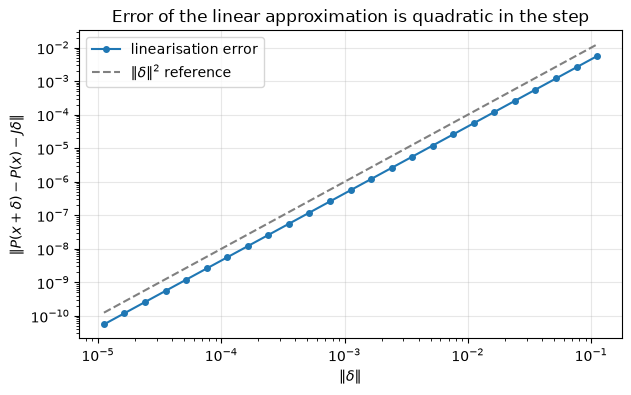

In [9]:
def polar(v):
    r, th = v
    return np.array([r * np.cos(th), r * np.sin(th)])

def jac_polar(v):
    r, th = v
    return np.array([[np.cos(th), -r * np.sin(th)],
                     [np.sin(th),  r * np.cos(th)]])

def jacobian_fd(F, x, h=1e-6):
    # numerical Jacobian: one central difference per input coordinate = one column each
    x = np.asarray(x, dtype=float)
    cols = []
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        cols.append((F(x + e) - F(x - e)) / (2 * h))
    return np.stack(cols, axis=1)

v0 = np.array([2.0, np.pi / 6])
print("analytic Jacobian:\n", jac_polar(v0))
print("numerical Jacobian:\n", jacobian_fd(polar, v0))
print("max |analytic - numerical| =", np.max(np.abs(jac_polar(v0) - jacobian_fd(polar, v0))))
print("determinant:", np.linalg.det(jac_polar(v0)), " (should equal r = 2)")

# linearisation: predicted vs exact change for a perturbation delta, then shrink delta
delta = np.array([0.1, 0.05])
print("\nJ delta        :", jac_polar(v0) @ delta)
print("exact change   :", polar(v0 + delta) - polar(v0))

scales = np.logspace(-4, 0, 25)
lin_err = [np.linalg.norm(polar(v0 + s * delta) - polar(v0) - jac_polar(v0) @ (s * delta)) for s in scales]
plt.loglog(scales * np.linalg.norm(delta), lin_err, "o-", ms=4, label="linearisation error")
plt.loglog(scales * np.linalg.norm(delta), (scales * np.linalg.norm(delta))**2, "--", color="gray", label=r"$\|\delta\|^2$ reference")
plt.xlabel(r"$\|\delta\|$"); plt.ylabel(r"$\|P(x+\delta) - P(x) - J\delta\|$")
plt.title("Error of the linear approximation is quadratic in the step"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [10]:
# chain rule in matrix form: compose polar with a linear map g(p) = A p + c
A = np.array([[1.0, 2.0], [0.0, -1.0], [3.0, 1.0]])     # g: R^2 -> R^3
c = np.array([0.5, 0.0, -1.0])
g_lin = lambda p: A @ p + c
h_comp = lambda v: g_lin(polar(v))                      # h = g o P : R^2 -> R^3

J_chain = A @ jac_polar(v0)                             # J_g (constant A) times J_P
J_num = jacobian_fd(h_comp, v0)
print("J_g J_P (3x2):\n", J_chain)
print("max |chain rule - numerical| =", np.max(np.abs(J_chain - J_num)))

# backprop preview: a vector-Jacobian product never forms J explicitly
gbar = np.array([1.0, -2.0, 0.5])                       # dL/dh, say
print("VJP  J^T gbar          :", J_chain.T @ gbar)
print("same via two VJPs      :", jac_polar(v0).T @ (A.T @ gbar))

J_g J_P (3x2):
 [[ 1.86603  2.4641 ]
 [-0.5     -1.73205]
 [ 3.09808 -1.26795]]
max |chain rule - numerical| = 5.023914617652281e-10
VJP  J^T gbar          : [4.41506 5.29423]
same via two VJPs      : [4.41506 5.29423]


The analytic and numerical Jacobians agree to about $10^{-10}$, and the linearisation error falls on
a line of slope 2 in the log-log plot — halve the step, quarter the error. The composed map's
Jacobian is the *product* $J_{\mathbf{g}}J_{\mathbf{P}}$ (shapes $3\times 2 = (3\times 2)(2\times 2)$),
and the backward pass of a network computes $J^\top\bar{\mathbf{g}}$ one factor at a time,
right to left, which is exactly what the last two lines show. Module 06 builds this machinery.

**Try it yourself:** evaluate `jac_polar` at `r = 0`. What happens to the determinant, and what does
that say about the inverse map (Cartesian to polar) at the origin?

## 5. The Hessian and second-order information

The Hessian $H_{ij} = \partial^2 f/\partial x_i\partial x_j$ is symmetric (Schwarz) and its
eigenvalues are the curvatures along its eigenvectors. At a critical point ($\nabla f = 0$):
all eigenvalues $> 0$ ⇒ minimum, all $< 0$ ⇒ maximum, mixed signs ⇒ saddle (even when some
eigenvalues are zero). Zero eigenvalues with the rest of one sign leave the test inconclusive.

We use $f(x,y) = x^4 - 2x^2 + y^2$ (a "double well"): critical points are $(\pm 1, 0)$ and
$(0, 0)$, and we also look at $g(x,y) = -(x^2+y^2)$ and the guide's $x^2 + 3xy + 5y^2$.

In [11]:
def hessian_fd(f, x, h=1e-4):
    # numerical Hessian via second central differences (h larger than for first derivatives:
    # the round-off error now scales like eps/h^2)
    x = np.asarray(x, dtype=float); n = x.size
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei = np.zeros(n); ei[i] = h
            ej = np.zeros(n); ej[j] = h
            H[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * h * h)
    return H

def classify(H, tol=1e-8):
    lam = np.linalg.eigvalsh(H)
    if np.any(lam > tol) and np.any(lam < -tol):
        return "saddle point", lam                  # mixed signs are conclusive, zeros or not
    if np.all(lam > tol):  return "local minimum", lam
    if np.all(lam < -tol): return "local maximum", lam
    return "degenerate (inconclusive)", lam         # some zeros, the rest of one sign

dwell = lambda v: v[0]**4 - 2 * v[0]**2 + v[1]**2
hess_dwell = lambda v: np.array([[12 * v[0]**2 - 4, 0.0], [0.0, 2.0]])

for cp in [np.array([1.0, 0.0]), np.array([-1.0, 0.0]), np.array([0.0, 0.0])]:
    H_an, H_num = hess_dwell(cp), hessian_fd(dwell, cp)
    kind, lam = classify(H_an)
    print(f"critical point {cp}: gradient {grad_fd(dwell, cp).round(6)}, eigenvalues {lam}, -> {kind}"
          f"   (numerical Hessian error {np.max(np.abs(H_an - H_num)):.1e})")

print()
for name, H in {"x^2+3xy+5y^2":   np.array([[2., 3.], [3., 10.]]),
                "x^2+3xy":        np.array([[2., 3.], [3., 0.]]),
                "-(x^2+y^2)":     np.array([[-2., 0.], [0., -2.]]),
                "diag(1, 0)":     np.diag([1., 0.]),
                "diag(-1, 0, 2)": np.diag([-1., 0., 2.])}.items():
    kind, lam = classify(H)
    print(f"{name:14s} eigenvalues {lam.round(4)} -> {kind}")

critical point [1. 0.]: gradient [-0.  0.], eigenvalues [2. 8.], -> local minimum   (numerical Hessian error 8.2e-08)
critical point [-1.  0.]: gradient [0. 0.], eigenvalues [2. 8.], -> local minimum   (numerical Hessian error 7.9e-08)
critical point [0. 0.]: gradient [0. 0.], eigenvalues [-4.  2.], -> saddle point   (numerical Hessian error 8.0e-08)

x^2+3xy+5y^2   eigenvalues [ 1. 11.] -> local minimum
x^2+3xy        eigenvalues [-2.1623  4.1623] -> saddle point
-(x^2+y^2)     eigenvalues [-2. -2.] -> local maximum
diag(1, 0)     eigenvalues [0. 1.] -> degenerate (inconclusive)
diag(-1, 0, 2) eigenvalues [-1.  0.  2.] -> saddle point


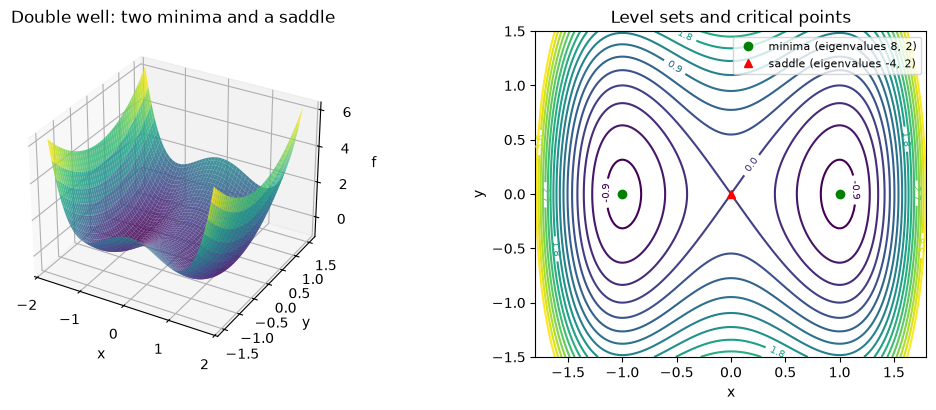

In [12]:
xs = np.linspace(-1.8, 1.8, 200); ys = np.linspace(-1.5, 1.5, 200)
X, Y = np.meshgrid(xs, ys)
Z = X**4 - 2 * X**2 + Y**2

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.85, linewidth=0)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.set_title("Double well: two minima and a saddle")
ax2 = fig.add_subplot(1, 2, 2)
lv = np.arange(-3, 14) * 0.3                        # integer steps keep the level f = 0 exact; label every third
cs = ax2.contour(X, Y, Z, levels=lv, cmap="viridis")
ax2.clabel(cs, lv[::3], inline=True, fontsize=7, fmt="%.1f")
ax2.plot([1, -1], [0, 0], "go", label="minima (eigenvalues 8, 2)")
ax2.plot([0], [0], "r^", label="saddle (eigenvalues -4, 2)")
ax2.set_aspect("equal")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_title("Level sets and critical points"); ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

At $(\pm 1, 0)$ both eigenvalues are positive (bowl); at the origin the Hessian has
eigenvalues $-4$ and $2$ — curving down along $x$, up along $y$ — a saddle, which is why the
level set $f = 0$ crosses itself there. The extra matrix $\mathrm{diag}(-1, 0, 2)$ is classified
as a saddle even though one eigenvalue is zero: once both signs appear, there is a direction
along which $f$ curves down and one along which it curves up. Only $\mathrm{diag}(1, 0)$, a
zero with the rest of one sign, is inconclusive. (A side note on `hessian_fd`: it uses
`h = 1e-4`, much larger than for first derivatives, because the second-difference formula
divides by $h^2$ and its round-off term is $\varepsilon/h^2$.)

The curvature along a unit direction $\mathbf{u}$ is the second derivative of the
one-dimensional slice $\varphi(t) = f(\mathbf{x}^* + t\mathbf{u})$, namely
$\varphi''(0) = \mathbf{u}^\top H\mathbf{u}$. Let us slice the double well through its saddle.

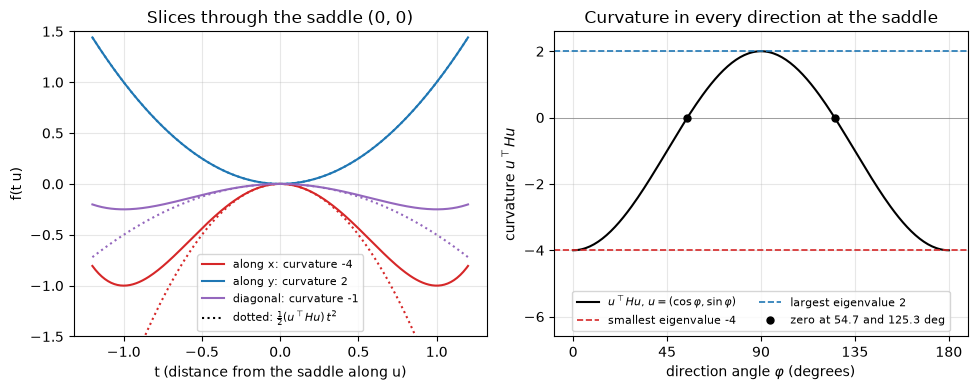

In [13]:
H0 = hess_dwell(np.zeros(2))                       # diag(-4, 2) at the saddle (0, 0)
t = np.linspace(-1.2, 1.2, 241)
slices = {"along x": (np.array([1.0, 0.0]), "C3"),
          "along y": (np.array([0.0, 1.0]), "C0"),
          "diagonal": (np.array([1.0, 1.0]) / np.sqrt(2), "C4")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, (u, col) in slices.items():
    curv = u @ H0 @ u
    ax1.plot(t, dwell(np.outer(u, t)), color=col, label=f"{name}: curvature {curv:g}")
    ax1.plot(t, 0.5 * curv * t**2, ":", color=col)
ax1.plot([], [], "k:", label=r"dotted: $\frac{1}{2}(u^\top H u)\,t^2$")
ax1.set_ylim(-1.5, 1.5)
ax1.set_xlabel("t (distance from the saddle along u)"); ax1.set_ylabel("f(t u)")
ax1.set_title("Slices through the saddle (0, 0)"); ax1.legend(fontsize=8, loc="lower center"); ax1.grid(alpha=0.3)

phi = np.linspace(0, np.pi, 181)
U_dir = np.stack([np.cos(phi), np.sin(phi)])       # unit directions as columns
curv_phi = np.einsum("in,ij,jn->n", U_dir, H0, U_dir)
lam0 = np.linalg.eigvalsh(H0)
phi0 = np.degrees(np.arctan(np.sqrt(-lam0[0] / lam0[1])))   # where -4 cos^2 + 2 sin^2 = 0
ax2.plot(np.degrees(phi), curv_phi, "k", label=r"$u^\top H u$, $u = (\cos\varphi, \sin\varphi)$")
ax2.axhline(lam0[0], color="C3", ls="--", lw=1.2, label=f"smallest eigenvalue {lam0[0]:g}")
ax2.axhline(lam0[1], color="C0", ls="--", lw=1.2, label=f"largest eigenvalue {lam0[1]:g}")
ax2.axhline(0, color="gray", lw=0.5)
ax2.plot([phi0, 180 - phi0], [0, 0], "ko", ms=5, label=f"zero at {phi0:.1f} and {180 - phi0:.1f} deg")
ax2.set_ylim(-6.6, 2.6); ax2.set_xticks(np.arange(0, 181, 45))
ax2.set_xlabel(r"direction angle $\varphi$ (degrees)"); ax2.set_ylabel(r"curvature $u^\top H u$")
ax2.set_title("Curvature in every direction at the saddle")
ax2.legend(fontsize=8, loc="lower center", ncol=2); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Notice that** each dotted parabola hugs its slice near $t = 0$: the slice curvature is exactly
$\mathbf{u}^\top H\mathbf{u}$, which is $-4$ along $x$, $+2$ along $y$ and $-1$ along the
diagonal — the average of the two eigenvalues, because the diagonal's squared components on the
two eigenvectors are both $1/2$. (Along $y$ the slice *is* its parabola.) Farther out, the
quartic term bends the $x$-slice back up into the two minima at $t = \pm 1$, so the quadratic
model is only local. The right panel shows that the curvature in every direction lies between the
smallest and the largest eigenvalue, reaches them exactly at the eigenvectors ($0^\circ$ and
$90^\circ$) and changes sign at $54.7^\circ$ and $125.3^\circ$: a saddle curves down in some
directions and up in others.

How typical is a minimum? Treat random symmetric matrices as the Hessians at random critical
points and count how often all their curvatures are positive.

n = 1: fraction of random symmetric matrices that are positive definite = 0.4992   (coin-flip estimate 2^-n = 0.5000)
n = 2: fraction of random symmetric matrices that are positive definite = 0.1474   (coin-flip estimate 2^-n = 0.2500)
n = 3: fraction of random symmetric matrices that are positive definite = 0.0255   (coin-flip estimate 2^-n = 0.1250)
n = 4: fraction of random symmetric matrices that are positive definite = 0.0021   (coin-flip estimate 2^-n = 0.0625)
n = 6: fraction of random symmetric matrices that are positive definite = 0.0000   (coin-flip estimate 2^-n = 0.0156)


n = 8: fraction of random symmetric matrices that are positive definite = 0.0000   (coin-flip estimate 2^-n = 0.0039)

200 x 200 matrix: fraction of positive eigenvalues = 0.505


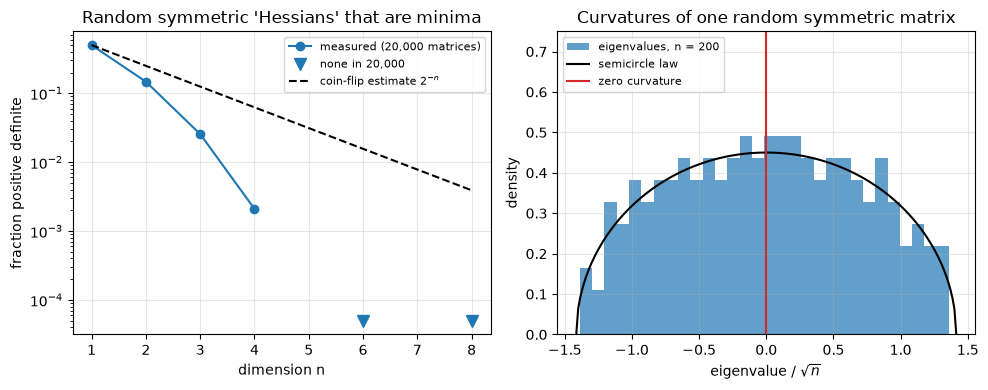

In [14]:
# saddles dominate in high dimensions: random symmetric "Hessians" at random critical points
trials, fracs = 20000, {}
for n in (1, 2, 3, 4, 6, 8):
    M = rng.standard_normal((trials, n, n)); M = (M + np.swapaxes(M, 1, 2)) / 2
    lam = np.linalg.eigvalsh(M)
    fracs[n] = np.mean(np.all(lam > 0, axis=1))
    print(f"n = {n}: fraction of random symmetric matrices that are positive definite = {fracs[n]:.4f}"
          f"   (coin-flip estimate 2^-n = {2.0**-n:.4f})")

# the eigenvalues of one large random symmetric matrix (a local generator: the global rng stream is unchanged)
rng_b = np.random.default_rng(1)
Mb = rng_b.standard_normal((200, 200)); Mb = (Mb + Mb.T) / 2
lam_b = np.linalg.eigvalsh(Mb) / np.sqrt(200)
print(f"\n200 x 200 matrix: fraction of positive eigenvalues = {np.mean(lam_b > 0):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
dims = np.array(sorted(fracs)); fr = np.array([fracs[d] for d in dims])
seen = fr > 0
nn = np.arange(1, 9)
ax1.semilogy(dims[seen], fr[seen], "o-", label="measured (20,000 matrices)")
ax1.semilogy(dims[~seen], np.full((~seen).sum(), 1 / trials), "v", color="C0", ms=8, label="none in 20,000")
ax1.semilogy(nn, 2.0**-nn, "k--", label=r"coin-flip estimate $2^{-n}$")
ax1.set_xlabel("dimension n"); ax1.set_ylabel("fraction positive definite")
ax1.set_title("Random symmetric 'Hessians' that are minima"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

ax2.hist(lam_b, bins=30, density=True, color="C0", alpha=0.7, label="eigenvalues, n = 200")
xx = np.linspace(-np.sqrt(2), np.sqrt(2), 200)
ax2.plot(xx, np.sqrt(np.clip(2 - xx**2, 0, None)) / np.pi, "k", label="semicircle law")
ax2.axvline(0, color="C3", lw=1.5, label="zero curvature")
ax2.set_xlabel(r"eigenvalue / $\sqrt{n}$"); ax2.set_ylabel("density")
ax2.set_ylim(0, 0.75)
ax2.set_title("Curvatures of one random symmetric matrix"); ax2.legend(fontsize=8, loc="upper left"); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Notice that** from $n = 2$ on the measured fraction falls below the coin-flip line ($0.147$
against $0.25$ at $n = 2$, $0.0021$ against $0.0625$ at $n = 4$), and not a single positive
definite matrix turns up among 20,000 draws for $n = 6$ or $8$. The coin-flip estimate treats the
$n$ eigenvalue signs as independent, but the eigenvalues of a random symmetric matrix repel each
other, so finding all of them on one side of zero is much rarer. The right panel shows where they
live: the curvatures fill a semicircle that is symmetric about zero, so about half of them
($49.5\,\%$ here) are negative. In a high-dimensional landscape, a point with zero gradient is
almost never a minimum.

## 6. Taylor expansion

$$f(a+h) = f(a) + f'(a)h + \frac{f''(a)}{2}h^2 + \dots + \frac{f^{(k)}(a)}{k!}h^k + O(h^{k+1}).$$

For $e^x$ about $0$ every derivative is $1$, so $T_k(x) = \sum_{j=0}^{k} x^j/j!$. We overlay the
polynomials on the function and then measure how the error scales with $|x|$.

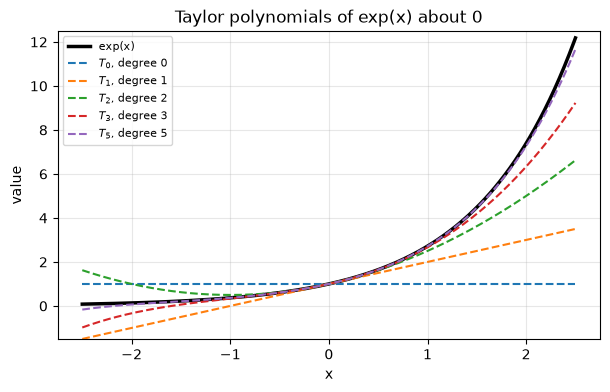

exp(0.5) = 1.6487212707001282
  degree 1: T_k = 1.500000, error = 1.49e-01
  degree 2: T_k = 1.625000, error = 2.37e-02
  degree 3: T_k = 1.645833, error = 2.89e-03
  degree 4: T_k = 1.648438, error = 2.84e-04


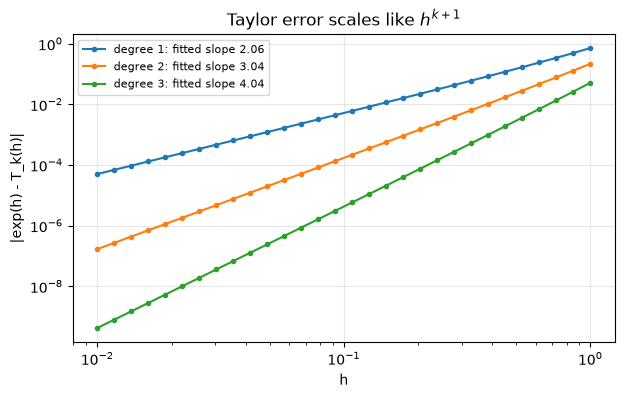

In [15]:
from math import factorial

def taylor_exp(x, k):
    return sum(x**j / factorial(j) for j in range(k + 1))

xs = np.linspace(-2.5, 2.5, 400)
plt.plot(xs, np.exp(xs), "k", lw=2.5, label="exp(x)")
for k in (0, 1, 2, 3, 5):
    plt.plot(xs, taylor_exp(xs, k), "--", label=f"$T_{k}$, degree {k}")
plt.ylim(-1.5, 12.5); plt.xlabel("x"); plt.ylabel("value"); plt.title("Taylor polynomials of exp(x) about 0")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print("exp(0.5) =", np.exp(0.5))
for k in (1, 2, 3, 4):
    print(f"  degree {k}: T_k = {taylor_exp(0.5, k):.6f}, error = {np.exp(0.5) - taylor_exp(0.5, k):.2e}")

# error scaling: for degree k, error ~ C h^(k+1)
hs = np.logspace(-2, 0, 30)
for k in (1, 2, 3):
    err = np.abs(np.exp(hs) - taylor_exp(hs, k))
    slope = np.polyfit(np.log(hs), np.log(err), 1)[0]
    plt.loglog(hs, err, "o-", ms=3, label=f"degree {k}: fitted slope {slope:.2f}")
plt.xlabel("h"); plt.ylabel("|exp(h) - T_k(h)|"); plt.title("Taylor error scales like $h^{k+1}$")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

Each extra term buys roughly one more correct digit at $x = 0.5$ (the error falls by a factor
of about $6$, $8$ and $10$, close to $(k+2)/x$), and the log-log slopes come out as $2, 3, 4$
for degrees $1, 2, 3$ — the remainder is $O(h^{k+1})$ as promised.
The polynomials are excellent near $0$ and useless far away: a Taylor model is *local*.

The multivariate version, $f(\mathbf{x}+\boldsymbol{\delta}) \approx f + \nabla f^\top\boldsymbol{\delta} + \tfrac12\boldsymbol{\delta}^\top H\boldsymbol{\delta}$,
is the model gradient descent and Newton's method minimise. One consequence: on a quadratic
with Hessian eigenvalues $\lambda_i$, a gradient step multiplies the error along each
eigendirection by $(1 - \eta\lambda_i)$, so the method is stable only for $\eta < 2/\lambda_{\max}$.

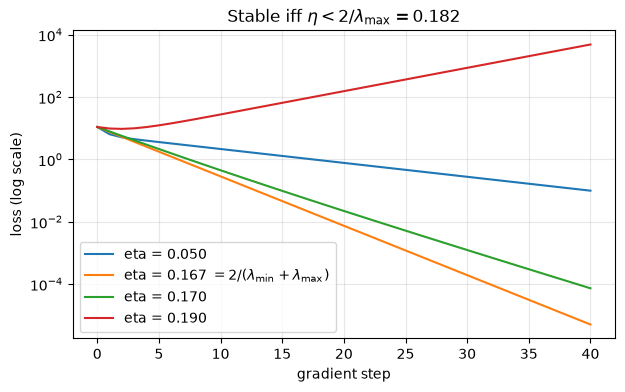

predicted contraction per step at eta = 1/6: 0.8333333333333334 (flat dir) and 0.8333333333333333 (sharp dir)


In [16]:
# gradient descent on the quadratic with Hessian [[2,3],[3,10]] (eigenvalues 1 and 11)
H = np.array([[2.0, 3.0], [3.0, 10.0]])
quad = lambda v: 0.5 * v @ H @ v
x_start = np.array([3.0, -2.0])

def run_gd(eta, steps=40):
    x = x_start.copy(); hist = [quad(x)]
    for _ in range(steps):
        x = x - eta * (H @ x)             # gradient of 0.5 x^T H x is H x (H symmetric)
        hist.append(quad(x))
    return np.array(hist)

lmin, lmax = np.linalg.eigvalsh(H)[[0, -1]]
for eta in (0.05, 1/6, 0.17, 0.19):
    hist = run_gd(eta)
    is_opt = np.isclose(eta, 2 / (lmin + lmax))    # the step that balances both directions
    plt.semilogy(hist, label=f"eta = {eta:.3f}" + (r" $= 2/(\lambda_{\min}+\lambda_{\max})$" if is_opt else ""))
plt.xlabel("gradient step"); plt.ylabel("loss (log scale)")
plt.title(rf"Stable iff $\eta < 2/\lambda_{{\max}} = {2 / lmax:.3f}$")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print("predicted contraction per step at eta = 1/6:", 1 - (1/6) * 1, "(flat dir) and", abs(1 - (1/6) * 11), "(sharp dir)")

With $\eta = 0.19 > 2/11$ the loss dips for two steps (the large flat component still shrinks
by a factor $0.81$ per step) and then explodes, because the sharp direction is multiplied by
$-1.09$ each step; with $\eta = 1/6$ both directions contract by $5/6$ per step. The learning
rate is dictated by the *largest* curvature while progress along the *smallest* curvature is
what takes long — the conditioning story of Module 05. To see the two directions separately,
follow the iterates themselves and split each one into its components along the eigenvectors
of $H$.

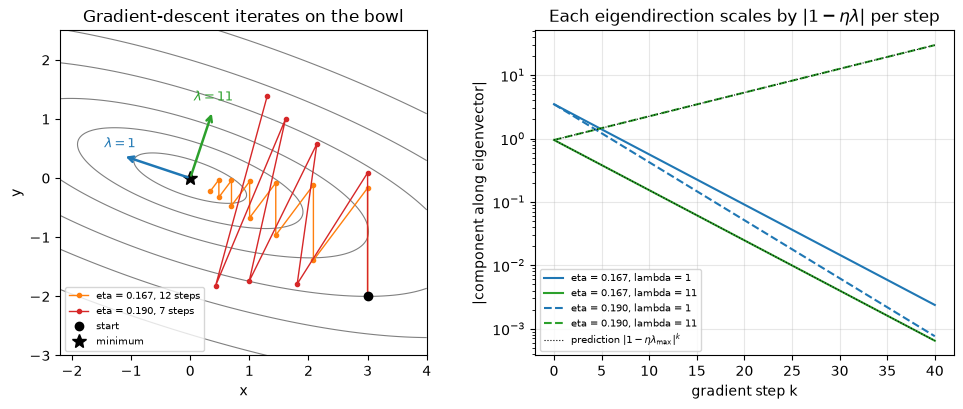

start components |Q^T x0|: [3.479 0.949]  eigenvalues: [ 1. 11.]


In [17]:
lam_H, Q = np.linalg.eigh(H)                       # eigenvalues (ascending) and eigenvectors

def gd_path(eta, steps):
    x = x_start.copy(); path = [x.copy()]
    for _ in range(steps):
        x = x - eta * (H @ x); path.append(x.copy())
    return np.array(path)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
gx_, gy_ = np.meshgrid(np.linspace(-2.2, 4, 200), np.linspace(-3, 2.5, 200))
Zq = 0.5 * (H[0, 0] * gx_**2 + 2 * H[0, 1] * gx_ * gy_ + H[1, 1] * gy_**2)
ax1.contour(gx_, gy_, Zq, levels=[0.5, 2, 5, 11, 20, 35], colors="gray", linewidths=0.8)
for eta, col, steps in ((1/6, "C1", 12), (0.19, "C3", 7)):
    P_ = gd_path(eta, steps)
    ax1.plot(P_[:, 0], P_[:, 1], "o-", color=col, ms=3, lw=1, label=f"eta = {eta:.3f}, {steps} steps")
ax1.plot(*x_start, "ko", label="start"); ax1.plot(0, 0, "k*", ms=10, label="minimum")
for i, col in enumerate(["C0", "C2"]):
    q = Q[:, i] * np.sign(Q[1, i])                 # orient both eigenvectors upwards
    ax1.annotate("", xy=1.2 * q, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
    ax1.text(*(1.25 * q + np.array([0.0, 0.12])), rf"$\lambda = {lam_H[i]:.0f}$", color=col, fontsize=9, ha="center")
ax1.set_aspect("equal"); ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Gradient-descent iterates on the bowl"); ax1.legend(fontsize=7, loc="lower left")

k = np.arange(41)
for eta, ls in ((1/6, "-"), (0.19, "--")):
    C_ = np.abs(gd_path(eta, 40) @ Q)              # |component| along each eigenvector
    for i, col in enumerate(["C0", "C2"]):
        ax2.semilogy(k, C_[:, i], ls, color=col, label=f"eta = {eta:.3f}, lambda = {lam_H[i]:.0f}")
    ax2.semilogy(k, C_[0, 1] * np.abs(1 - eta * lam_H[1])**k, "k:", lw=0.8)
ax2.plot([], [], "k:", lw=0.8, label=r"prediction $|1-\eta\lambda_{\max}|^k$")
ax2.set_xlabel("gradient step k"); ax2.set_ylabel("|component along eigenvector|")
ax2.set_title(r"Each eigendirection scales by $|1-\eta\lambda|$ per step")
ax2.legend(fontsize=7); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print("start components |Q^T x0|:", np.abs(Q.T @ x_start).round(3), " eigenvalues:", lam_H)

**Notice that** at $\eta = 1/6$ the two solid lines fall in parallel: both components shrink by
exactly $5/6$ per step (from $3.48$ and $0.95$ to below $10^{-2}$ after 40 steps), while the
orange path still zig-zags across the valley, because the sharp factor $1 - 11/6 = -5/6$ flips
its sign every step. At $\eta = 0.19$ the flat component converges even faster (factor $0.81$),
but the sharp one grows by $1.09$ per step to about $30$. The exploding red loss curve above is
this single direction, and its sign flips are the widening zig-zag of the red path on the left.

**Try it yourself:** replace `H` by `[[1, 0], [0, 100]]` (condition number 100). How many steps
does the flat direction now need at the largest stable learning rate?

## 7. Matrix calculus identities, verified numerically

| expression | gradient |
|---|---|
| $\mathbf{a}^\top\mathbf{x}$ | $\mathbf{a}$ |
| $\mathbf{x}^\top A\mathbf{x}$ | $(A + A^\top)\mathbf{x}$ |
| $\lVert B\mathbf{x}-\mathbf{b}\rVert^2$ | $2B^\top(B\mathbf{x}-\mathbf{b})$ |
| $\operatorname{tr}(XA)$ | $A^\top$ |
| $\log\det X$ | $X^{-\top}$ |

Random matrices plus `grad_fd` from Section 3 give an independent check of each row. Note
that `A` below is deliberately *not* symmetric, so $2A\mathbf{x}$ would be wrong.

In [18]:
n, m = 4, 6
a = rng.standard_normal(n)
A = rng.standard_normal((n, n))                 # NOT symmetric on purpose
B = rng.standard_normal((m, n))
b = rng.standard_normal(m)
x = rng.standard_normal(n)

checks = {
    "grad a^T x = a":                     (grad_fd(lambda v: a @ v, x),                     a),
    "grad x^T A x = (A + A^T) x":         (grad_fd(lambda v: v @ A @ v, x),                 (A + A.T) @ x),
    "grad x^T A x != 2 A x (asym. A)":    (grad_fd(lambda v: v @ A @ v, x),                 2 * A @ x),
    "grad ||Bx - b||^2 = 2 B^T (Bx - b)": (grad_fd(lambda v: np.sum((B @ v - b)**2), x),    2 * B.T @ (B @ x - b)),
}
for name, (num, ana) in checks.items():
    print(f"{name:36s} max |numerical - formula| = {np.max(np.abs(num - ana)):.2e}")

# matrix-valued inputs: flatten X to use the same finite-difference helper
X = rng.standard_normal((3, 3)) + 4 * np.eye(3)          # well-conditioned, positive determinant
C = rng.standard_normal((3, 3))
g_tr = grad_fd(lambda v: np.trace(v.reshape(3, 3) @ C), X.ravel()).reshape(3, 3)
g_ld = grad_fd(lambda v: np.log(np.linalg.det(v.reshape(3, 3))), X.ravel()).reshape(3, 3)
print(f"{'grad tr(XC) = C^T':36s} max error = {np.max(np.abs(g_tr - C.T)):.2e}")
print(f"{'grad log det X = X^-T':36s} max error = {np.max(np.abs(g_ld - np.linalg.inv(X).T)):.2e}")

grad a^T x = a                       max |numerical - formula| = 6.61e-11
grad x^T A x = (A + A^T) x           max |numerical - formula| = 2.44e-10
grad x^T A x != 2 A x (asym. A)      max |numerical - formula| = 3.14e+00
grad ||Bx - b||^2 = 2 B^T (Bx - b)   max |numerical - formula| = 5.36e-09
grad tr(XC) = C^T                    max error = 1.01e-09
grad log det X = X^-T                max error = 1.89e-10


In [19]:
# least squares: gradient = 0  <=>  normal equations. The guide's 3-point line fit:
B3 = np.array([[1., 0.], [1., 1.], [1., 2.]]); b3 = np.array([1., 2., 2.])
loss = lambda v: np.sum((B3 @ v - b3)**2)
grad_ls = lambda v: 2 * B3.T @ (B3 @ v - b3)

x0 = np.array([0.0, 1.0])
print("loss at x0 =", loss(x0), "  gradient =", grad_ls(x0), "  numerical:", grad_fd(loss, x0))

x_star = np.linalg.solve(B3.T @ B3, B3.T @ b3)
print("normal-equation solution x* =", x_star, "  loss* =", loss(x_star))
print("gradient at x* =", grad_ls(x_star).round(12), "  (zero: first-order optimality)")
print("residual at x* =", (B3 @ x_star - b3).round(6), "  B^T residual =", (B3.T @ (B3 @ x_star - b3)).round(12))
print("np.linalg.lstsq agrees:", np.allclose(np.linalg.lstsq(B3, b3, rcond=None)[0], x_star))

loss at x0 = 2.0   gradient = [-4. -2.]   numerical: [-4. -2.]
normal-equation solution x* = [1.16667 0.5    ]   loss* = 0.16666666666666669
gradient at x* = [-0. -0.]   (zero: first-order optimality)
residual at x* = [ 0.16667 -0.33333  0.16667]   B^T residual = [-0. -0.]
np.linalg.lstsq agrees: True


Every identity matches finite differences to about $10^{-8}$ or better (absolute error; the
least-squares gradient has entries of size $\sim 10$, and the last digits vary from machine to
machine), and the row labelled
`!= 2 A x` shows a large error — the $A^\top$ is not optional for a non-symmetric $A$. The
least-squares block is Module 02's normal equations rediscovered as "set the gradient to
zero": at $\mathbf{x}^*$ the residual is orthogonal to the columns of $B$ (that is what
$B^\top\mathbf{r}^* = \mathbf{0}$ says) and `np.linalg.lstsq` returns the same point.

## 8. Gradients of ML losses: logistic regression by hand

With $z_i = \mathbf{w}^\top\mathbf{x}_i$, $p_i = \sigma(z_i)$ and the binary cross-entropy
$L = -\frac1n\sum_i [y_i\ln p_i + (1-y_i)\ln(1-p_i)]$, the chain rule gives the famously
clean result

$$\frac{\partial L}{\partial z_i} = \frac{p_i - y_i}{n}, \qquad \nabla_{\mathbf{w}} L = \frac1n X^\top(\mathbf{p} - \mathbf{y}).$$

We check it on a synthetic dataset, take a few gradient steps and watch the loss fall and
the predictions become calibrated in aggregate.

In [20]:
# synthetic 2-feature dataset with an intercept column
n = 200
X_raw = rng.standard_normal((n, 2))
w_true = np.array([0.5, 2.0, -1.5])                     # intercept, w1, w2
X = np.column_stack([np.ones(n), X_raw])
p_true = sigmoid(X @ w_true)
y = (rng.random(n) < p_true).astype(float)

def bce_loss(w):
    z = X @ w
    # numerically stable: log(1+exp(-z)) = softplus(-z), and -log(1-p) = softplus(z)
    return np.mean(np.logaddexp(0, -z) * y + np.logaddexp(0, z) * (1 - y))

def bce_grad(w):
    p = sigmoid(X @ w)
    return X.T @ (p - y) / n

w0 = np.zeros(3)
print("analytic gradient :", bce_grad(w0))
print("numerical gradient:", grad_fd(bce_loss, w0))
print("relative error    :", np.linalg.norm(bce_grad(w0) - grad_fd(bce_loss, w0)) / np.linalg.norm(bce_grad(w0)))

analytic gradient : [-0.005   -0.24123  0.22477]
numerical gradient: [-0.005   -0.24123  0.22477]
relative error    : 2.9400382961655905e-10


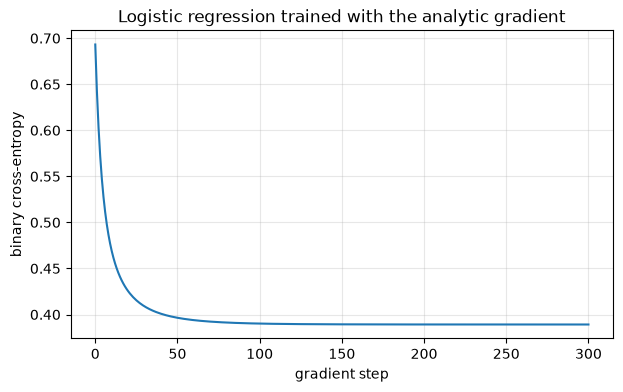

learned w        : [ 0.40437  2.15587 -1.6541 ]
true  w          : [ 0.5  2.  -1.5]
mean prediction  : 0.5049439498286181    positive rate: 0.505   (calibration in aggregate)
||gradient|| at end: 0.00028141250957480036
accuracy         : 0.805


In [21]:
w, eta = np.zeros(3), 0.5
hist, gnorm_hist, gap_hist = [bce_loss(w)], [], []
for step in range(300):
    g_w = bce_grad(w)
    gnorm_hist.append(np.linalg.norm(g_w))                       # recorded for the next plot
    gap_hist.append(abs(sigmoid(X @ w).mean() - y.mean()))       # calibration gap before the step
    w = w - eta * g_w
    hist.append(bce_loss(w))

plt.plot(hist); plt.xlabel("gradient step"); plt.ylabel("binary cross-entropy")
plt.title("Logistic regression trained with the analytic gradient"); plt.grid(alpha=0.3); plt.show()

p_hat = sigmoid(X @ w)
print("learned w        :", w)
print("true  w          :", w_true)
print("mean prediction  :", p_hat.mean(), "   positive rate:", y.mean(), "  (calibration in aggregate)")
print("||gradient|| at end:", np.linalg.norm(bce_grad(w)))
print("accuracy         :", np.mean((p_hat > 0.5) == (y == 1)))

The analytic gradient $X^\top(\mathbf{p}-\mathbf{y})/n$ matches finite differences to about
$10^{-10}$ in relative error, the loss decreases monotonically with a reasonable step size
(logistic loss is convex), and at the end the mean predicted probability equals the empirical
positive rate — the intercept component of "$\nabla L = 0$" reads $\sum_i p_i = \sum_i y_i$.
The learned weights sit near the true ones, with the discrepancy you would expect from 200 noisy
labels. The next plot shows the fitted boundary and follows the calibration gap during training.

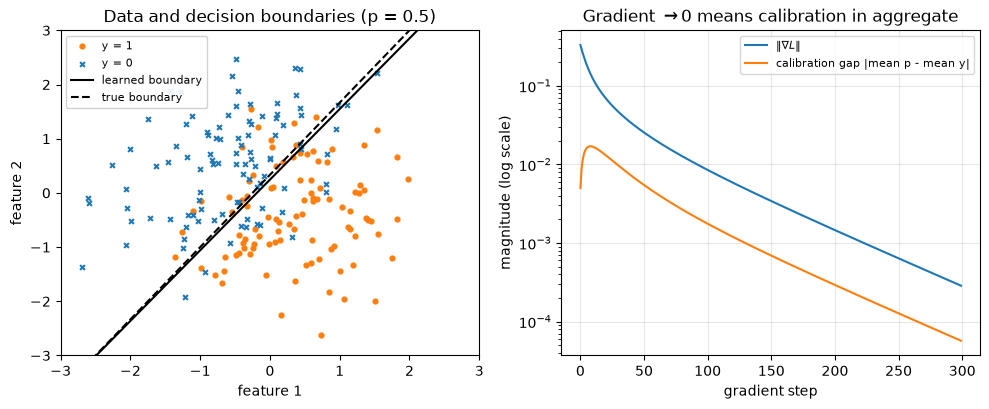

calibration gap: start 0.0050, peak 0.0170 at step 8, end 5.6e-05
intercept component of the final gradient: -5.6050171381888946e-05  = mean p - mean y


In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], s=12, c="C1", label="y = 1")
ax1.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], s=12, c="C0", marker="x", label="y = 0")
x1 = np.linspace(-3, 3, 50)
ax1.plot(x1, -(w[0] + w[1] * x1) / w[2], "k", label="learned boundary")
ax1.plot(x1, -(w_true[0] + w_true[1] * x1) / w_true[2], "k--", label="true boundary")
ax1.set_xlim(-3, 3); ax1.set_ylim(-3, 3)
ax1.set_xlabel("feature 1"); ax1.set_ylabel("feature 2")
ax1.set_title("Data and decision boundaries (p = 0.5)"); ax1.legend(fontsize=8, loc="upper left", framealpha=0.9)

ax2.semilogy(gnorm_hist, label=r"$\|\nabla L\|$")
ax2.semilogy(gap_hist, label=r"calibration gap |mean p - mean y|")
ax2.set_xlabel("gradient step"); ax2.set_ylabel("magnitude (log scale)")
ax2.set_title(r"Gradient $\to 0$ means calibration in aggregate"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"calibration gap: start {gap_hist[0]:.4f}, peak {max(gap_hist):.4f} at step {int(np.argmax(gap_hist))}, "
      f"end {abs(sigmoid(X @ w).mean() - y.mean()):.1e}")
print("intercept component of the final gradient:", bce_grad(w)[0], " = mean p - mean y")

**Notice that** the learned boundary lies almost on top of the true one, and that the
calibration gap is one coordinate of the gradient: because the first column of $X$ is all ones,
the intercept component of $\nabla L$ is exactly $\frac1n\sum_i (p_i - y_i)$, the mean
prediction minus the positive rate. The gap starts at $0.005$ (every $p_i = 0.5$ against a
positive rate of $0.505$), rises briefly to about $0.017$ near step 8 while the slopes are being
learned, then falls in parallel with $\lVert\nabla L\rVert$ (which ends near $3\times10^{-4}$)
to about $6\times10^{-5}$. Aggregate calibration is not an extra property of logistic regression;
it is the intercept component of $\nabla L = \mathbf{0}$.

**Try it yourself:** set `eta = 5.0`. Does the convex loss still decrease at every step? Then
replace `bce_loss` by the squared error `np.mean((sigmoid(X @ w) - y)**2)` and `bce_grad` by its
gradient `2 * X.T @ ((p - y) * p * (1 - p)) / n` (check it with `grad_fd` first: the factor $2$
from the square is easy to drop) — compare the speed of training and the final calibration.

## Summary

- A derivative is a sensitivity and the slope of the best linear approximation; a central
  difference estimates it with error $O(h^2)$ until round-off ($\varepsilon/h$) takes over around
  $h \approx 10^{-6}$ — the V-shaped error curve.
- The chain rule multiplies slopes; the activation derivatives $\sigma(1-\sigma)$,
  $1-\tanh^2$ and the ReLU mask are what backprop multiplies by, and $\sigma' \le 1/4$ is why
  deep sigmoid networks vanish.
- The gradient is the direction of steepest ascent (Cauchy–Schwarz) and is perpendicular to
  level sets; directional derivatives are $\nabla f^\top\mathbf{u}$.
- The Jacobian linearises a vector map; Jacobians of composed maps multiply; backprop
  computes $J^\top\bar{\mathbf{g}}$ one layer at a time.
- The Hessian's eigenvalues classify critical points; in high dimensions almost all critical
  points are saddles; $\eta < 2/\lambda_{\max}$ keeps gradient descent stable.
- Taylor models are local: the degree-$k$ error scales as $h^{k+1}$; gradient descent and
  Newton's method minimise first- and second-order Taylor models.
- $\nabla \mathbf{x}^\top A\mathbf{x} = (A+A^\top)\mathbf{x}$ and
  $\nabla\lVert B\mathbf{x}-\mathbf{b}\rVert^2 = 2B^\top(B\mathbf{x}-\mathbf{b})$; setting the latter
  to zero gives the normal equations.
- Logistic loss has gradient $X^\top(\mathbf{p}-\mathbf{y})/n$, which makes the fitted model
  calibrated in aggregate — and every one of these formulas was confirmed with finite differences.

**Next:** open `exercises.ipynb` and implement these ideas yourself, ending with a reusable
gradient checker.